# 1 - Importar as bibliotecas

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.callbacks import EarlyStopping

# 2 - Gerar as quatro distribuições gaussianas
Vamos gerar 2.000 amostras para cada classe. Cada amostra terá oito características.

In [2]:
# Quantidade de amostras por classe
n_amostras = 2000

# Médias das quatro distribuições
medias = np.array([
    [0, 0, 0, 0, 0, 0, 0, 0],
    [4, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 0, 4, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 4]
])

# Desvio padrão igual a 1 (variância igual a 1)
desvio = 1

# Gerar os dados de cada distribuição
dados = []
classes = []

for i, media in enumerate(medias):
    amostras = np.random.normal(
        loc=media,
        scale=desvio,
        size=(n_amostras, 8)
    )

    dados.append(amostras)
    classes.extend([i] * n_amostras)

# Juntar todas as distribuições
X = np.vstack(dados)
y = np.array(classes)

print("Formato dos dados:", X.shape)
print("Formato das classes:", y.shape)

Formato dos dados: (8000, 8)
Formato das classes: (8000,)


# 3 - Separar os dados para treinamento e teste
Vamos reservar 20% das amostras para testar o autoencoder em dados que ele não utilizou durante o treinamento.

In [3]:
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Treinamento:", X_treino.shape)
print("Teste:", X_teste.shape)

Treinamento: (6400, 8)
Teste: (1600, 8)


# 4 - Normalizar os dados
A normalização ajuda a rede neural durante o treinamento. Vamos ajustar o normalizador somente com os dados de treinamento.

In [4]:
scaler = StandardScaler()

X_treino = scaler.fit_transform(X_treino)
X_teste = scaler.transform(X_teste)

# 5 - Construir o Autoencoder
Agora vamos montar a rede neural.

O Encoder recebe oito características e as comprime até duas dimensões. O Decoder recebe essas duas dimensões e tenta reconstruir as oito características originais.

In [5]:
# Entrada com 8 características
entrada = Input(shape=(8,))

# Encoder: comprime os dados
encoder = Dense(6, activation='relu')(entrada)
encoder = Dense(4, activation='relu')(encoder)
representacao = Dense(2, activation='linear', name='espaco_latente')(encoder)

# Decoder: reconstrói os dados
decoder = Dense(4, activation='relu')(representacao)
decoder = Dense(6, activation='relu')(decoder)
saida = Dense(8, activation='linear')(decoder)

# Modelo completo
autoencoder = Model(entrada, saida)

# Compilar
autoencoder.compile(
    optimizer='adam',
    loss='mse'
)

autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6)              │            54 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │            28 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ espaco_latente (Dense)          │ (None, 2)              │            10 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │            12 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 6)              │            30 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 8)              │            56 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 190 (760.00 B)

 Trainable params: 190 (760.00 B)

 Non-trainable params: 0 (0.00 B)

# 6 - Treinar a rede

In [6]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True
)

historico = autoencoder.fit(
    X_treino,
    X_treino,
    epochs=200,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/200
160/160 ━━━━━━━━━━━━━━━━━━━━ 7s 12ms/step - loss: 0.9963 - val_loss: 0.9580
Epoch 2/200
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.9420 - val_loss: 0.9099
Epoch 3/200
160/160 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.9052 - val_loss: 0.8812
Epoch 4/200
160/160 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.8764 - val_loss: 0.8587
Epoch 5/200
160/160 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.8633 - val_loss: 0.8524
Epoch 6/200
160/160 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.8575 - val_loss: 0.8470
Epoch 7/200
160/160 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.8517 - val_loss: 0.8407
Epoch 8/200
160/160 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.8418 - val_loss: 0.8244
Epoch 9/200
160/160 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.8089 - val_loss: 0.7858
Epoch 10/200
160/160 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.7797 - val_loss: 0.7657
Epoch 11/200
160/160 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.7610 - val_loss: 0.7483
Epoch 12/200
160/160 ━━━━━━━━━━━━━━━━━━━

#7 - Visualizar o erro de treinamento

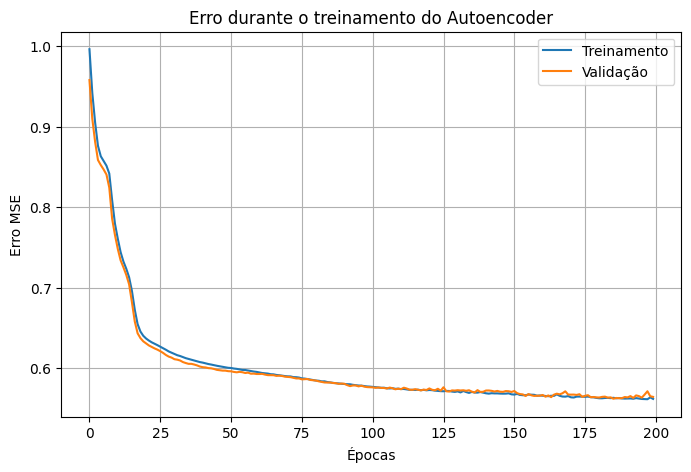

In [7]:
plt.figure(figsize=(8, 5))

plt.plot(historico.history['loss'], label='Treinamento')
plt.plot(historico.history['val_loss'], label='Validação')

plt.xlabel('Épocas')
plt.ylabel('Erro MSE')
plt.title('Erro durante o treinamento do Autoencoder')
plt.legend()
plt.grid()
plt.show()

#8 - Extrair a representação em duas dimensões
Agora vamos utilizar somente o Encoder para transformar os dados originais em duas dimensões.

In [8]:
# Criar modelo que retorna somente o espaço latente
encoder_model = Model(
    inputs=autoencoder.input,
    outputs=autoencoder.get_layer('espaco_latente').output
)

# Reduzir os dados de teste para duas dimensões
X_reduzido = encoder_model.predict(X_teste)

print("Formato original:", X_teste.shape)
print("Formato reduzido:", X_reduzido.shape)

50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
Formato original: (1600, 8)
Formato reduzido: (1600, 2)


# 9 - Visualizar as quatro classes em duas dimensões
Esta é a etapa principal da atividade. Vamos criar um gráfico de dispersão usando as duas dimensões produzidas pelo Encoder. As cores representam as quatro distribuições gaussianas.

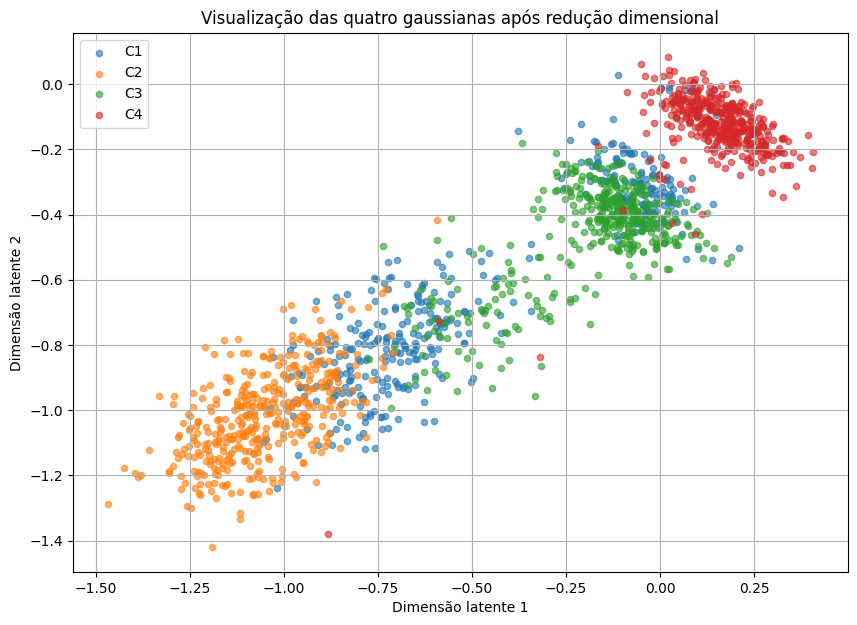

In [9]:
nomes_classes = ['C1', 'C2', 'C3', 'C4']

plt.figure(figsize=(10, 7))

for i in range(4):
    mascara = y_teste == i

    plt.scatter(
        X_reduzido[mascara, 0],
        X_reduzido[mascara, 1],
        label=nomes_classes[i],
        alpha=0.6,
        s=20
    )

plt.xlabel('Dimensão latente 1')
plt.ylabel('Dimensão latente 2')
plt.title('Visualização das quatro gaussianas após redução dimensional')
plt.legend()
plt.grid()
plt.show()

#10 - Avaliar a reconstrução
Também é interessante verificar se o autoencoder conseguiu reconstruir os dados originais.

In [10]:
# Reconstruir os dados de teste
X_reconstruido = autoencoder.predict(X_teste)

# Calcular o erro médio quadrático
mse = np.mean((X_teste - X_reconstruido) ** 2)

print(f"Erro médio quadrático da reconstrução: {mse:.4f}")

50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
Erro médio quadrático da reconstrução: 0.5660
